In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
# from sidm.studies.dy_jets import function_dy

utilities.set_plot_style()
%matplotlib inline

In [2]:
channels=  [ 
    "cr_Zmumu_noLJ_noVeto",
    "cr_Zmumu_noLJ",

           ]

samples_separate = [
    # "TTJets",
    "DYJetsToLL",
    # "QCD",
    # "Diboson",
              # "data"
              ]
samples = ["bgs",
           "data", 
           # "TTJets",
               "DYJetsToLL",
               # "QCD",
               # "Diboson",
          ]
sum_hist= {}
for channel_name in channels:
    sum_hist[channel_name] = {}
for s in samples:
    if s == "data":
        list1= functions.get_data_files()
        list1 =  [x for x in list1 if "C" in x]
    elif s == "bgs":
        list1=[]
        for y in samples_separate:
            list2 = functions.get_bg_file_names(y)
            list1.extend(list2)
    else:
        list1 = functions.get_bg_file_names(s)
    for channel_name in channels:
        folder_name = f"OutputFiles/{channel_name}/2026_10_27"
        sum_h= utilities.sum_hist(list1, folder_name)
        sum_hist[channel_name][s] = sum_h



In [3]:
sum_hist[channels[1]]["bgs"].keys()

dict_keys(['muon_eta_phi_pixelHits', 'muon_PixelHits_vs_genAs_toMu_Lxy', 'dsaMuon_eta_phi', 'photon_eta_phi', 'mu_lj_eta_phi', 'egm_lj_eta_phi', 'jet_eta_phi', 'electron_eta_phi'])

cr_Zmumu_noLJ_noVeto
bgs
('muon_eta', 'muon_phi', 'muon_trkNumPixelHits')
muon_eta
muon_phi
muon_trkNumPixelHits
data
('muon_eta', 'muon_phi', 'muon_trkNumPixelHits')
muon_eta
muon_phi
muon_trkNumPixelHits
cr_Zmumu_noLJ
bgs
('muon_eta', 'muon_phi', 'muon_trkNumPixelHits')
muon_eta
muon_phi
muon_trkNumPixelHits
data
('muon_eta', 'muon_phi', 'muon_trkNumPixelHits')
muon_eta
muon_phi
muon_trkNumPixelHits


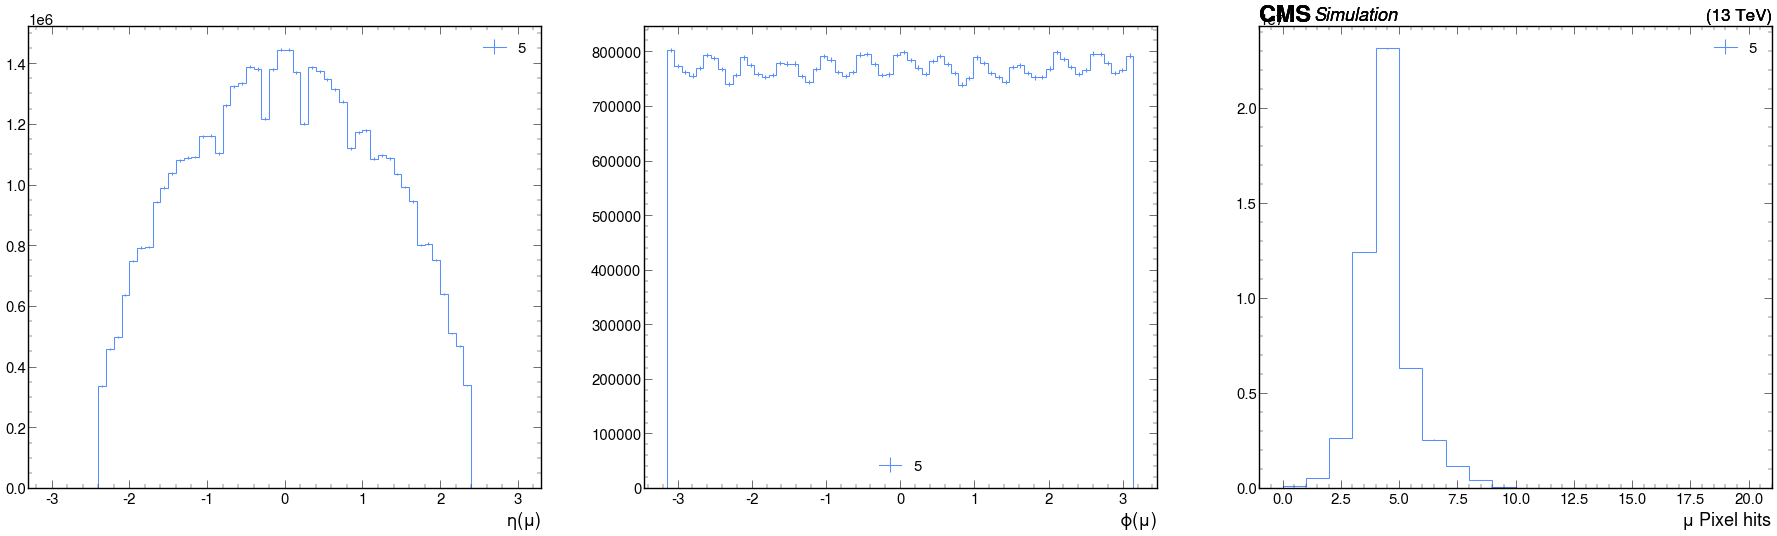

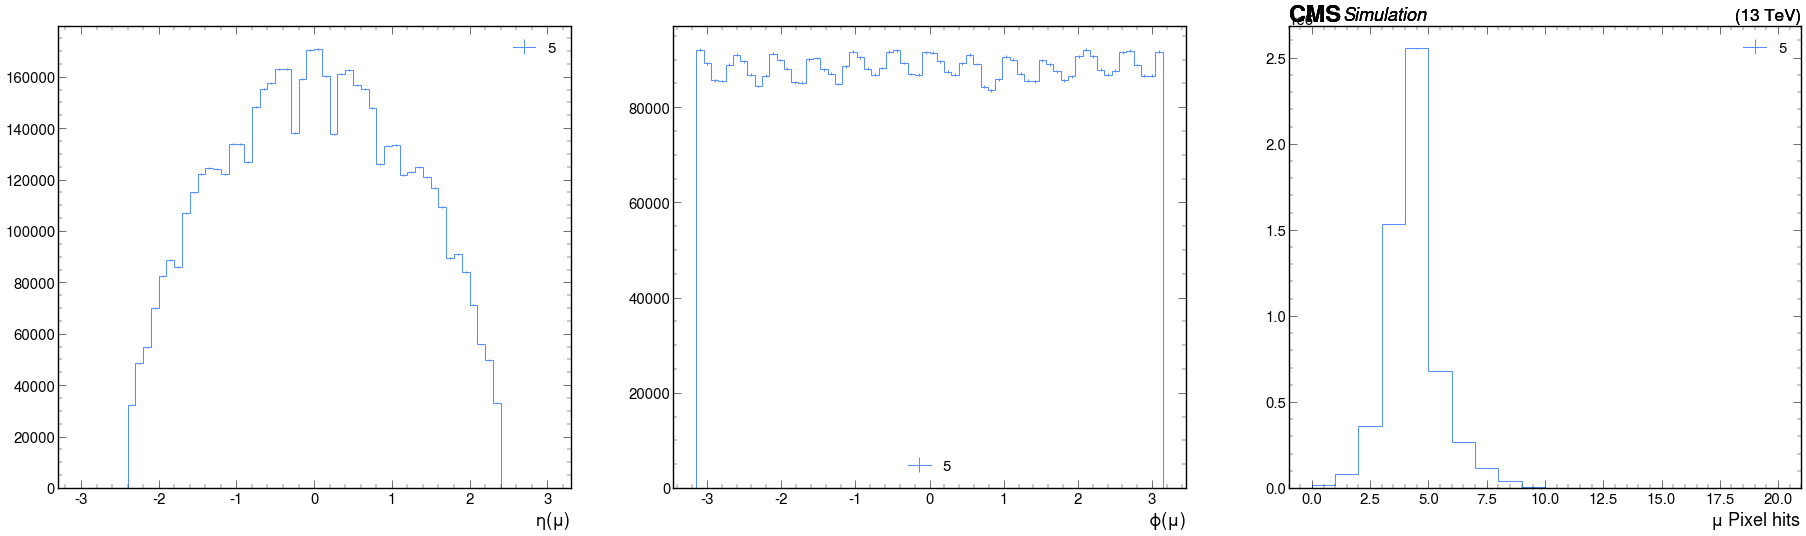

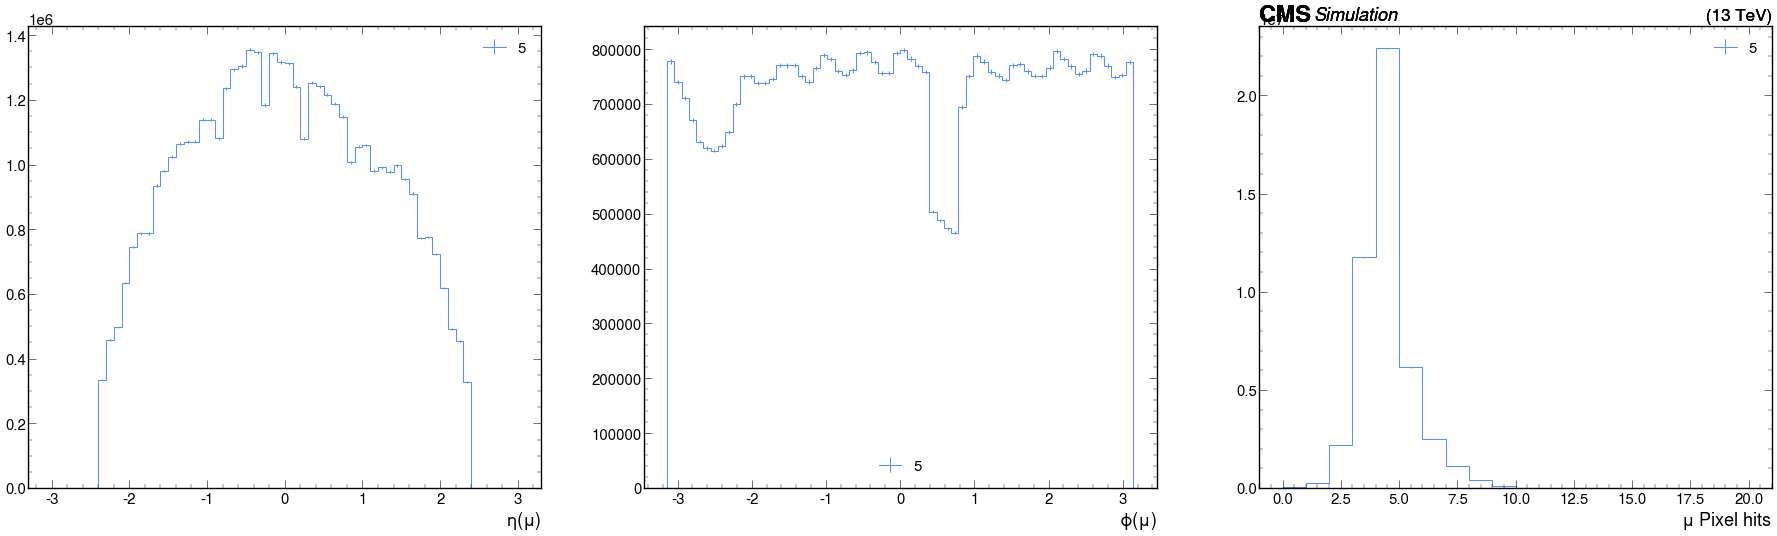

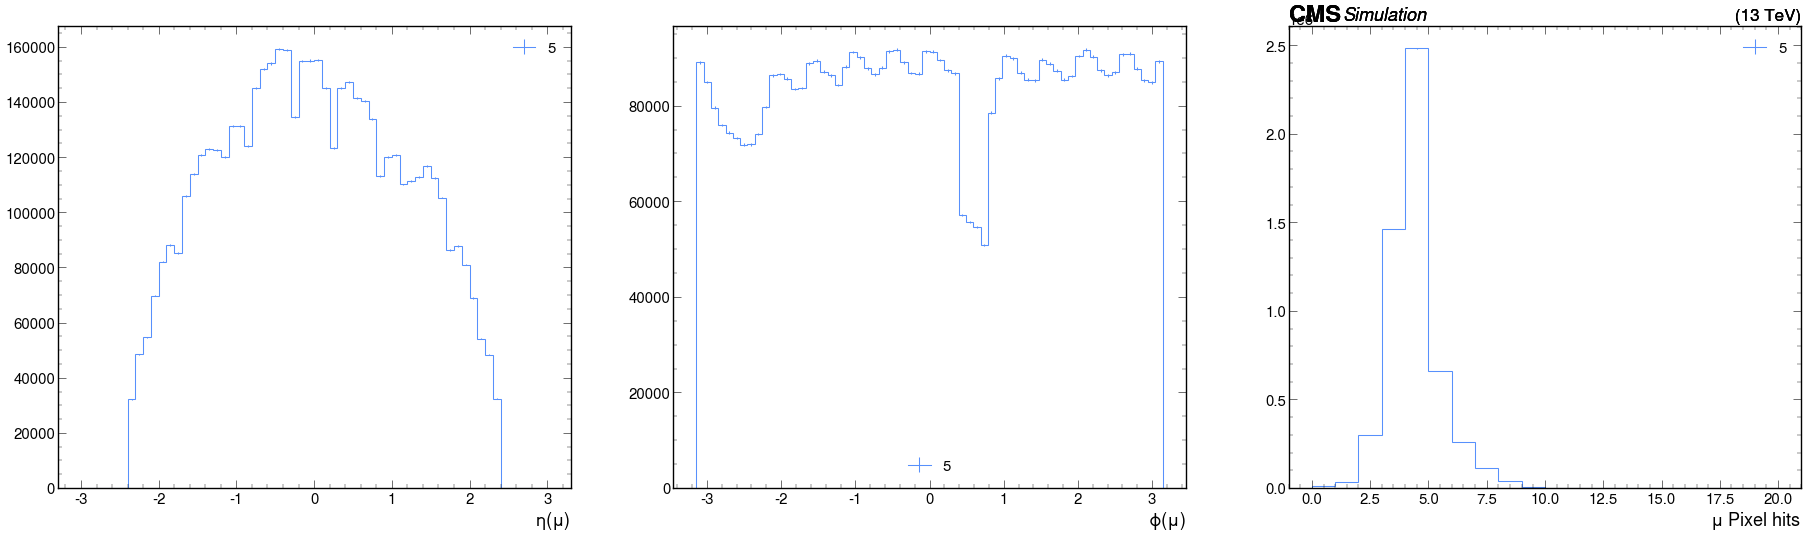

In [13]:
for i, channel_name  in enumerate(channels):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)
        histogram  = sum_hist[channel_name][s]["muon_eta_phi_pixelHits"][channel_name, :, :, :]
        # print(histogram)#[channel_name, :, :, :]
        print(histogram.axes.name)
        n = len(histogram.axes.name)
        fig, axs =  plt.subplots(1, n, figsize = (n*15, 12))
        for p, k in enumerate(histogram.axes.name):
            print(k)
            utilities.plot(histogram.project(k), ax =axs[p], label=5)

        for ax in axs:
            ax.legend()
        
    

cr_Zmumu_noLJ_noVeto
bgs
data
cr_Zmumu_noLJ
bgs
data


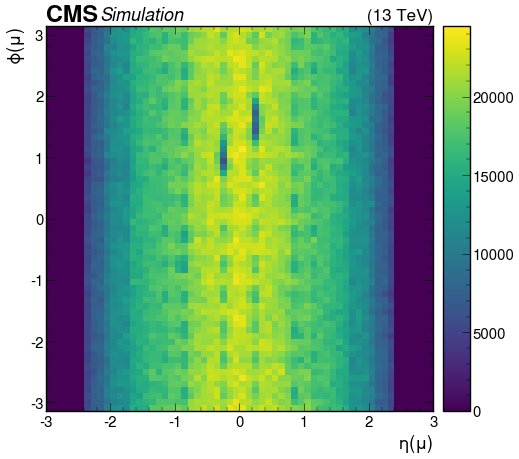

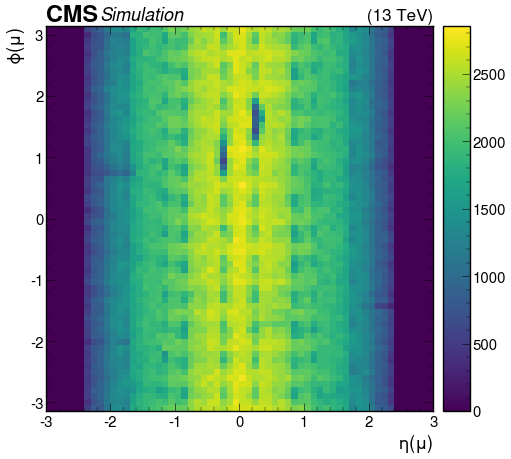

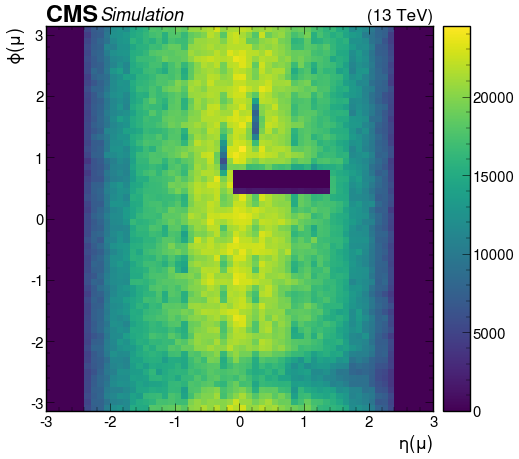

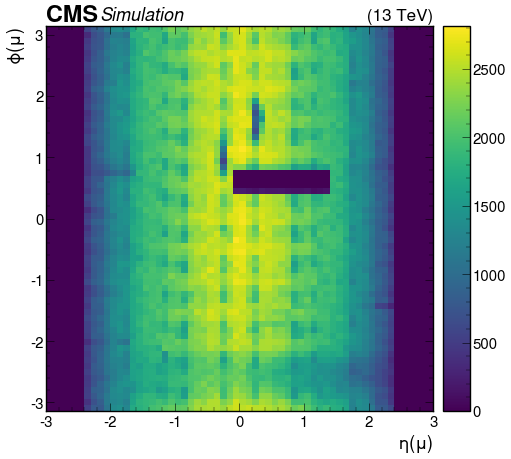

<Figure size 500x500 with 0 Axes>

In [5]:
for i, channel_name  in enumerate(channels):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)
        histogram  = sum_hist[channel_name][s]["muon_eta_phi_pixelHits"][channel_name, :, :, :]
        # print(histogram.axes.name)
        # n = len(histogram.axes.name)
        utilities.plot(histogram.project("muon_eta", "muon_phi"), label=s)
        plt.figure()
        
    

In [6]:
axis = histogram.axes["muon_trkNumPixelHits"]

print("Axis:", axis)
print("Edges:", axis.edges)
print("Centers:", axis.centers)

Axis: Regular(20, 0, 20, name='muon_trkNumPixelHits', label='$\\mu$ Pixel hits')
Edges: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20.]
Centers: [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5]


cr_Zmumu_noLJ_noVeto
bgs
data
cr_Zmumu_noLJ
bgs
data


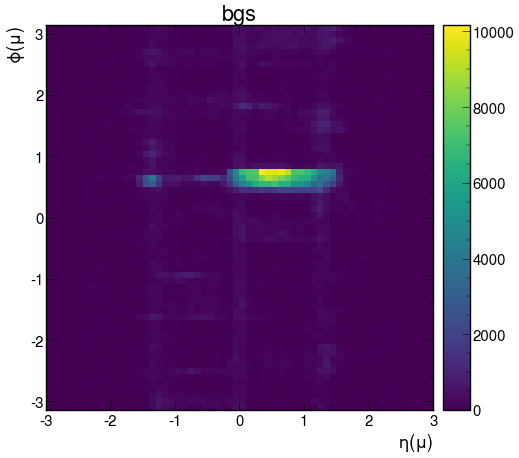

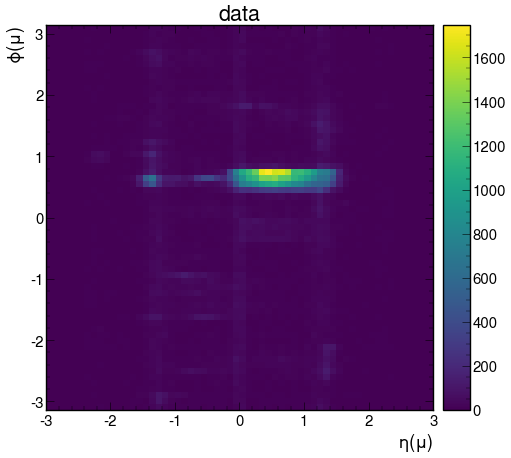

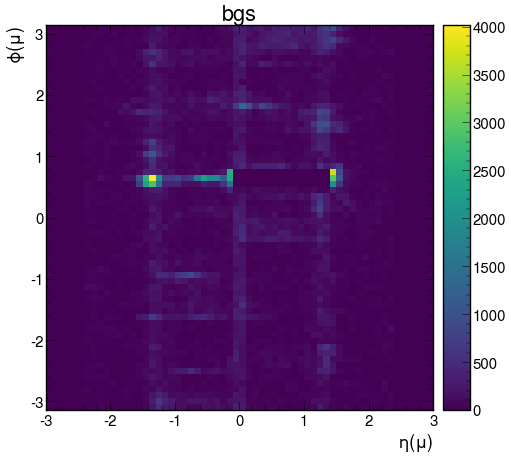

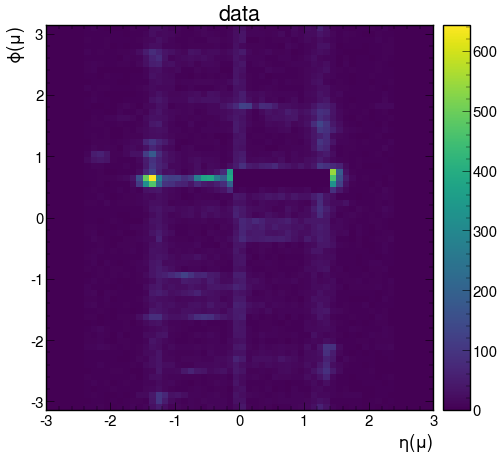

<Figure size 500x500 with 0 Axes>

In [7]:
for i, channel_name in enumerate(channels):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)

        histogram = sum_hist[channel_name][s]["muon_eta_phi_pixelHits"][
            channel_name, :, :, :
        ]

        projection = histogram[
            {"muon_trkNumPixelHits":slice(0, 2, sum)}
        ].project("muon_eta", "muon_phi")

        utilities.plot(projection, label=s, skip_label=True)
        plt.title(s)
        plt.figure()

cr_Zmumu_noLJ_noVeto
bgs
data
cr_Zmumu_noLJ
bgs
data


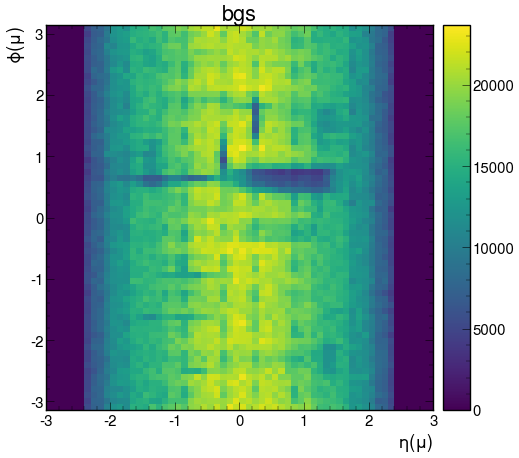

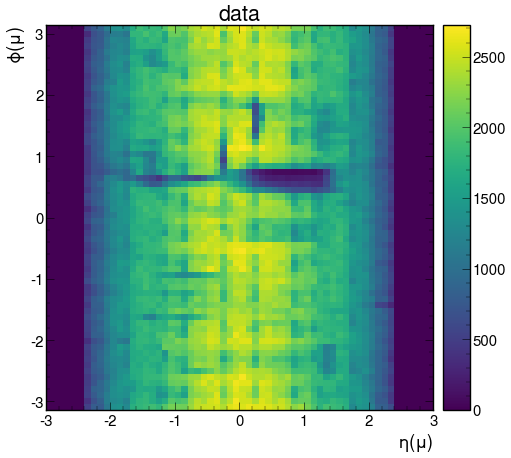

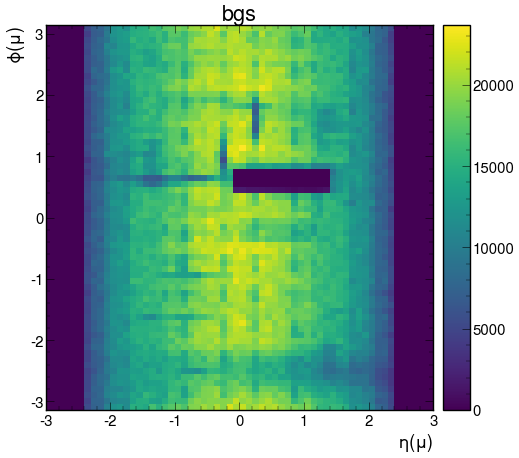

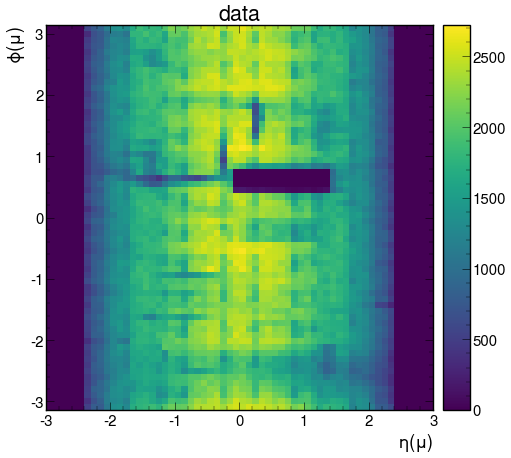

<Figure size 500x500 with 0 Axes>

In [8]:
for i, channel_name in enumerate(channels):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)

        histogram = sum_hist[channel_name][s]["muon_eta_phi_pixelHits"][
            channel_name, :, :, :
        ]

        projection = histogram[
            {"muon_trkNumPixelHits":slice(3, 20, sum)}
        ].project("muon_eta", "muon_phi")

        utilities.plot(projection, label=s, skip_label=True)
        plt.title(s)
        plt.figure()

In [9]:

import numpy as np
def normalize_hist(hist):
    values = hist.values()
    variances = hist.variances()
    bin_widths = np.diff(hist.axes[0].edges)

    norm = np.sum(values * bin_widths)

    if norm == 0:
        raise ValueError("Cannot normalize histogram with zero integral")

    hist.values()[...] = values / norm
    hist.variances()[...] = variances / norm**2

    return hist

cr_Zmumu_noLJ_noVeto
bgs
data
cr_Zmumu_noLJ
bgs
data


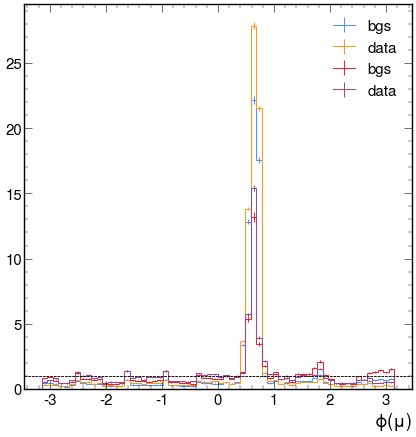

In [10]:
for i, channel_name in enumerate(channels):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)

        histogram = sum_hist[channel_name][s]["muon_eta_phi_pixelHits"][
            channel_name, :, :, :
        ]

        projection_prompt = histogram[
            {"muon_trkNumPixelHits":slice(3, 20, sum)}
        ].project( "muon_phi")
        projection_displaced = histogram[
            {"muon_trkNumPixelHits":slice(0, 2, sum)}
        ].project( "muon_phi")

        prompt_hist = normalize_hist(projection_prompt)
        disp_hist = normalize_hist(projection_displaced)

        ratio, err = utilities._gaussian_ratio(disp_hist, prompt_hist)

        utilities.plot(ratio, yerr=err, label=s, skip_label=True)
    plt.legend()
    
    plt.axhline(y=1, color="black", linestyle="--", linewidth=1)

cr_Zmumu_noLJ_noVeto
bgs
data


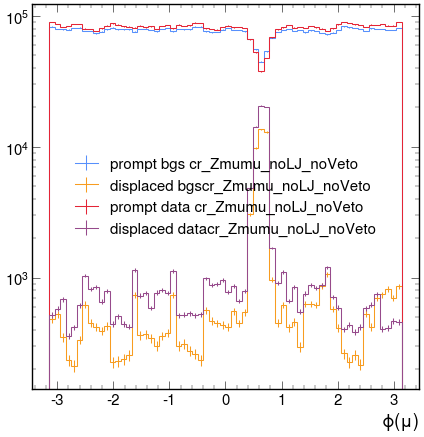

In [11]:
r = 6.616/62.061775847

for i, channel_name in enumerate(channels[:1]):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)

        histogram = sum_hist[channel_name][s]["muon_eta_phi_pixelHits"][
            channel_name, :, :, :
        ]

        projection_prompt = histogram[
            {"muon_trkNumPixelHits":slice(3, 20, sum)}
        ].project( "muon_phi")
        projection_displaced = histogram[
            {"muon_trkNumPixelHits":slice(0, 2, sum)}
        ].project( "muon_phi")

        if s !="data":
            projection_prompt =  r*projection_prompt
            projection_displaced = r*projection_displaced

        utilities.plot(projection_prompt, label=f"prompt {s} {channel_name}", skip_label=True)
        utilities.plot(projection_displaced, label=f"displaced {s}{channel_name}", skip_label=True)
    plt.legend()
    plt.yscale("log")
    
    # plt.axhline(y=1, color="black", linestyle="--", linewidth=1)

cr_Zmumu_noLJ
bgs
data


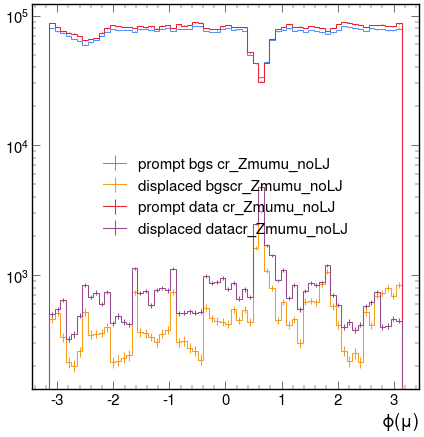

In [12]:
r = 6.616/62.061775847

for i, channel_name in enumerate(channels[1:]):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)

        histogram = sum_hist[channel_name][s]["muon_eta_phi_pixelHits"][
            channel_name, :, :, :
        ]

        projection_prompt = histogram[
            {"muon_trkNumPixelHits":slice(3, 20, sum)}
        ].project( "muon_phi")
        projection_displaced = histogram[
            {"muon_trkNumPixelHits":slice(0, 2, sum)}
        ].project( "muon_phi")

        if s !="data":
            projection_prompt =  r*projection_prompt
            projection_displaced = r*projection_displaced

        utilities.plot(projection_prompt, label=f"prompt {s} {channel_name}", skip_label=True)
        utilities.plot(projection_displaced, label=f"displaced {s}{channel_name}", skip_label=True)
    plt.legend()
    plt.yscale("log")
    
    # plt.axhline(y=1, color="black", linestyle="--", linewidth=1)

cr_Zmumu_noLJ_noVeto
bgs
('dsaMuons_eta', 'dsaMuons_phi')
data
('dsaMuons_eta', 'dsaMuons_phi')
cr_Zmumu_noLJ
bgs
('dsaMuons_eta', 'dsaMuons_phi')


/tmp/ipykernel_433/1875769723.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


data
('dsaMuons_eta', 'dsaMuons_phi')


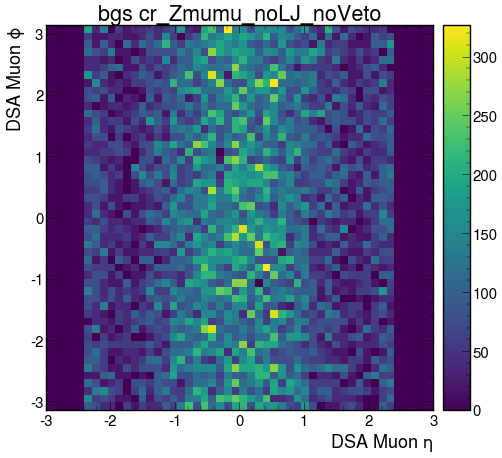

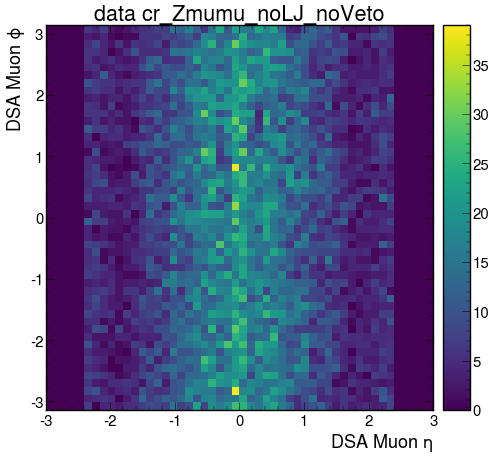

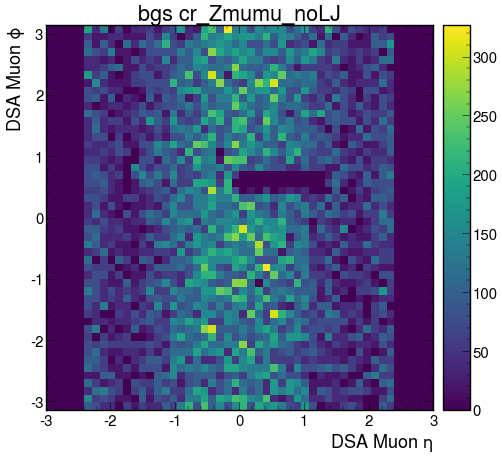

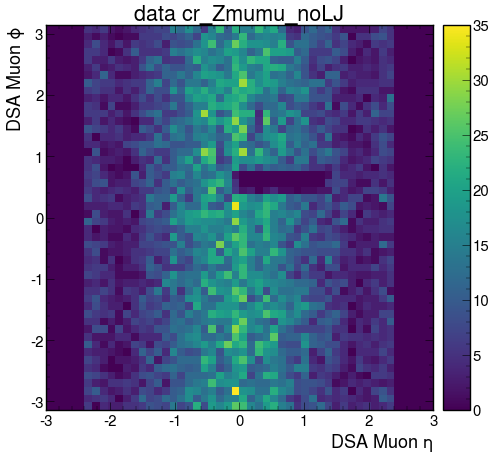

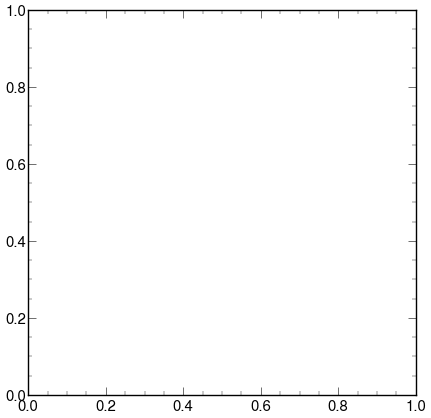

In [24]:
r = 6.616/62.061775847

for i, channel_name in enumerate(channels):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)

        histogram = sum_hist[channel_name][s]["dsaMuon_eta_phi"][
            channel_name, :, :
        ]
        print(histogram.axes.name)

        # projection_prompt = histogram.project( "dsaMuons_eta")
        # projection_displaced = histogram.project( "dsaMuons_eta")

        # if s !="data":
        #     projection_prompt =  r*projection_prompt
        #     projection_displaced = r*projection_displaced

        utilities.plot(histogram, skip_label=True)
        plt.title(s +" " +channel_name)
        plt.figure()
        # utilities.plot(projection_displaced, label=f"displaced {s}{channel_name}", skip_label=True)
    plt.legend()
    # plt.yscale("log")
    
    # plt.axhline(y=1, color="black", linestyle="--", linewidth=1)

cr_Zmumu_noLJ_noVeto
bgs
('electrons_eta', 'electrons_phi')
data
('electrons_eta', 'electrons_phi')


/tmp/ipykernel_433/3176611230.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


cr_Zmumu_noLJ
bgs
('electrons_eta', 'electrons_phi')
data
('electrons_eta', 'electrons_phi')


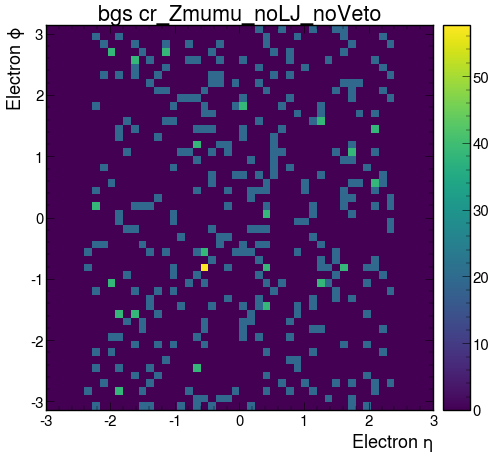

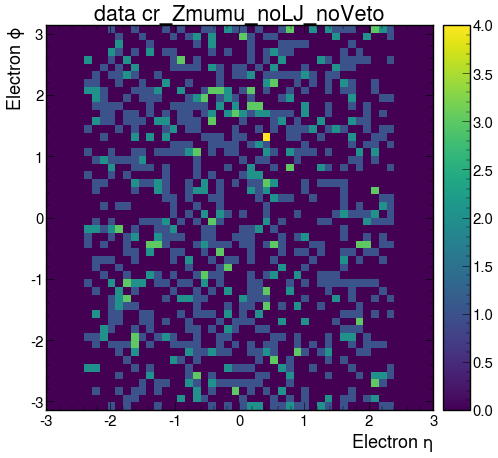

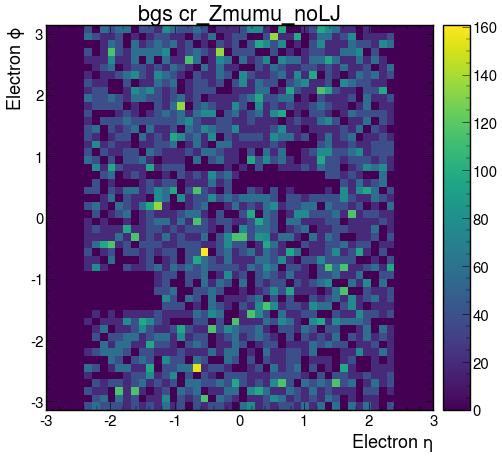

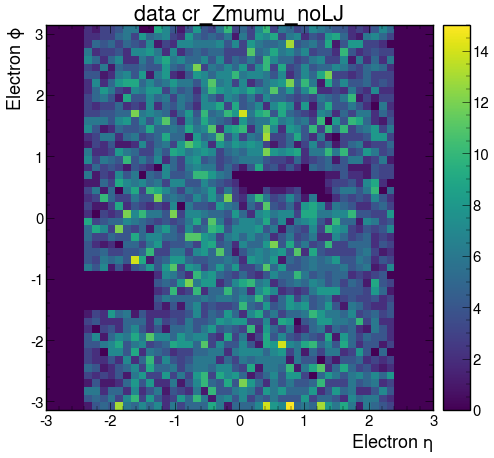

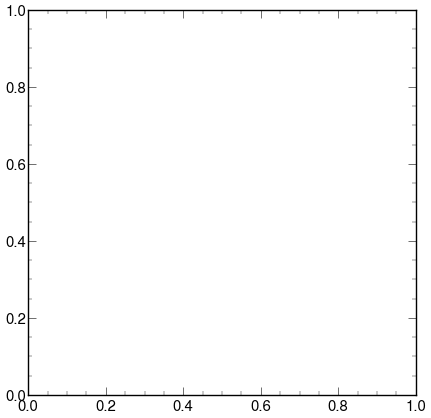

In [25]:
r = 6.616/62.061775847

for i, channel_name in enumerate(channels):
    print(channel_name)
    for j, s in enumerate(samples[:2]):
        print(s)

        histogram = sum_hist[channel_name][s]["electron_eta_phi"][
            channel_name, :, :
        ]
        print(histogram.axes.name)

        # projection_prompt = histogram.project( "dsaMuons_eta")
        # projection_displaced = histogram.project( "dsaMuons_eta")

        # if s !="data":
        #     projection_prompt =  r*projection_prompt
        #     projection_displaced = r*projection_displaced

        utilities.plot(histogram, skip_label=True)
        plt.title(s +" " +channel_name)
        plt.figure()
        # utilities.plot(projection_displaced, label=f"displaced {s}{channel_name}", skip_label=True)
    plt.legend()
    # plt.yscale("log")
    
    # plt.axhline(y=1, color="black", linestyle="--", linewidth=1)